# 03 — Q-learning

Unlike value iteration, the agent now **does not know the model**. It only calls `env.reset()` and
`env.step(action)`, and learns by trial and error. It fills a table $Q(s, a)$: its own estimate of
the return obtained by taking action $a$ in state $s$ and behaving well afterwards.

## The update rule

**Q-learning** (off-policy TD control, Sutton & Barto, eq. 6.8), applied after every step:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \Big[\underbrace{R_{t+1} + \gamma \max_a Q(S_{t+1}, a)}_{\text{TD target}} - Q(S_t, A_t)\Big]$$

- The term in brackets is the **TD error**: what the agent has just observed minus what it expected.
- $\alpha$ (learning rate) sets how much the estimate is corrected each time.
- After **STOP** (*terminated*) there is no future: the target is just $R_{t+1}$.
- After the **50-step limit** (*truncated*) the state is not terminal: we keep $\gamma \max_a Q(S_{t+1}, a)$.

It is **off-policy**: the agent behaves $\varepsilon$-greedily (it explores), but the target uses
$\max_a Q$, i.e. the value of the *greedy* policy. It learns about the best policy while exploring.

## Algorithm (Sutton & Barto, section 6.5)

```
Initialise Q(s, a) = 0 for all s, a
For each episode:
    S <- reset()                                   (random natural starting point, pen up)
    Repeat until STOP or 50 steps:
        A <- epsilon-greedy action from Q(S, .)
        take A, observe R, S'
        Q(S, A) <- Q(S, A) + alpha [R + gamma max_a Q(S', a) - Q(S, A)]     (target = R if STOP)
        S <- S'
```

## Exploration: $\varepsilon$-greedy

With probability $\varepsilon$ the agent plays a random action, otherwise $\arg\max_a Q(S, a)$
(ties broken at random). $\varepsilon$ decreases linearly from 1 to 0.05 during the first 80 % of the
episodes: the agent explores everything at the beginning, then mostly exploits what it has learned.

## Parameters

| Parameter | Value | Why |
|---|---|---|
| $\alpha$ | 0.5 | the environment is deterministic, one observation is reliable: we can correct strongly |
| $\gamma$ | 0.99 | same as value iteration, so that the returns can be compared with $v_*$ |
| $\varepsilon$ | 1 → 0.05 | linear decay over 80 % of the episodes |
| episodes | 30,000 per letter | |
| runs | 5 per letter | 5 different random seeds, to see whether the result depends on luck |

## How we evaluate

Every 500 training episodes, we pause and play the **greedy policy** (no exploration) from every
natural starting point. We record its mean discounted return, compared with the optimum $v_*$
computed by value iteration in notebook 02, and whether it draws the letter **perfectly**
(complete, no segment outside the letter, then STOP).

In [1]:
import sys
sys.path.insert(0, "..")

import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

from src.letters import TRAINING_LETTERS
from src.environment import LetterWritingEnv
from src.tabular_agents import q_learning, epsilon_schedule
from src.evaluation import play_policy, greedy_policy
from src.visualization import plot_episodes, animate_episodes, SURFACE, TEXT, MUTED

GAMMA = 0.99
N_EPISODES = 30_000
ALPHA = 0.5
SEEDS = [0, 1, 2, 3, 4]

# Optimal returns computed by value iteration (notebook 02 must have been run first)
optimal = {}
with open("../results/02_optimal_returns.csv") as f:
    for row in csv.DictReader(f):
        optimal[(row["letter"], row["start"])] = {"v_star": float(row["v_star"]), "steps": int(row["steps"]),
                                                  "strokes": int(row["strokes"])}
v_star_mean = {name: np.mean([v["v_star"] for (n, _), v in optimal.items() if n == name]) for name in TRAINING_LETTERS}
print("optimal mean return per letter:", {k: round(v, 3) for k, v in v_star_mean.items()})


def style(ax, title=None, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#ecebe7", lw=0.8)
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    if title:
        ax.set_title(title, color=TEXT, fontsize=10)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED, fontsize=9)

optimal mean return per letter: {'I': np.float64(8.69), 'L': np.float64(8.018), 'T': np.float64(8.694), 'E': np.float64(11.947), 'F': np.float64(9.541), 'H': np.float64(11.839), 'N': np.float64(12.266), 'Z': np.float64(12.266), 'V': np.float64(8.885), 'X': np.float64(8.518)}


## 1. One letter in detail: L

One run (seed 0). We also save the greedy policy at several moments of the training, to see the
agent go from scribbling to clean drawing.

training time: 2.5 s
final greedy return: 8.018   (optimum v* = 8.018)
first perfect drawing from every starting point after 4,750 episodes


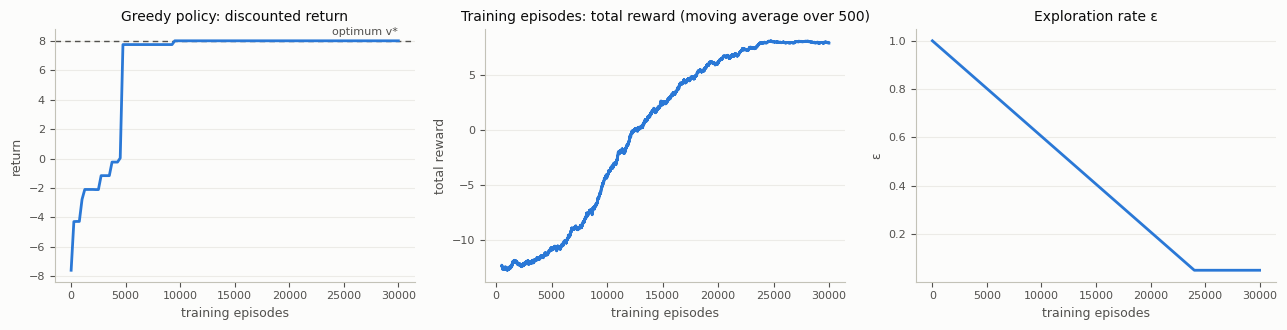

In [2]:
SNAPSHOTS = (0, 500, 1_000, 2_000, 5_000, 10_000, 30_000)
env = LetterWritingEnv("L")
res_L = q_learning(env, n_episodes=N_EPISODES, alpha=ALPHA, gamma=GAMMA, eval_every=250,
                   snapshot_episodes=SNAPSHOTS, seed=0)
print(f"training time: {res_L['time']:.1f} s")
print(f"final greedy return: {res_L['eval_return'][-1]:.3f}   (optimum v* = {v_star_mean['L']:.3f})")
first_perfect = res_L["eval_episodes"][np.argmax(res_L["eval_perfect"] == 1)]
print(f"first perfect drawing from every starting point after {first_perfect:,} episodes")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), facecolor=SURFACE)
ax = axes[0]
ax.axhline(v_star_mean["L"], color=MUTED, lw=1, ls=(0, (4, 3)))
ax.text(N_EPISODES, v_star_mean["L"] + 0.4, "optimum v*", ha="right", fontsize=8, color=MUTED)
ax.plot(res_L["eval_episodes"], res_L["eval_return"], color="#2a78d6", lw=2)
style(ax, "Greedy policy: discounted return", "training episodes", "return")

ax = axes[1]
window = 500
smooth = np.convolve(res_L["train_returns"], np.ones(window) / window, mode="valid")
ax.plot(np.arange(window, len(res_L["train_returns"]) + 1), smooth, color="#2a78d6", lw=2)
style(ax, f"Training episodes: total reward (moving average over {window})", "training episodes", "total reward")

ax = axes[2]
episodes = np.arange(N_EPISODES)
ax.plot(episodes, [epsilon_schedule(e, N_EPISODES) for e in episodes], color="#2a78d6", lw=2)
style(ax, "Exploration rate ε", "training episodes", "ε")
fig.tight_layout()
fig.savefig("../results/03_L_learning.png", dpi=150, facecolor=SURFACE)
plt.show()

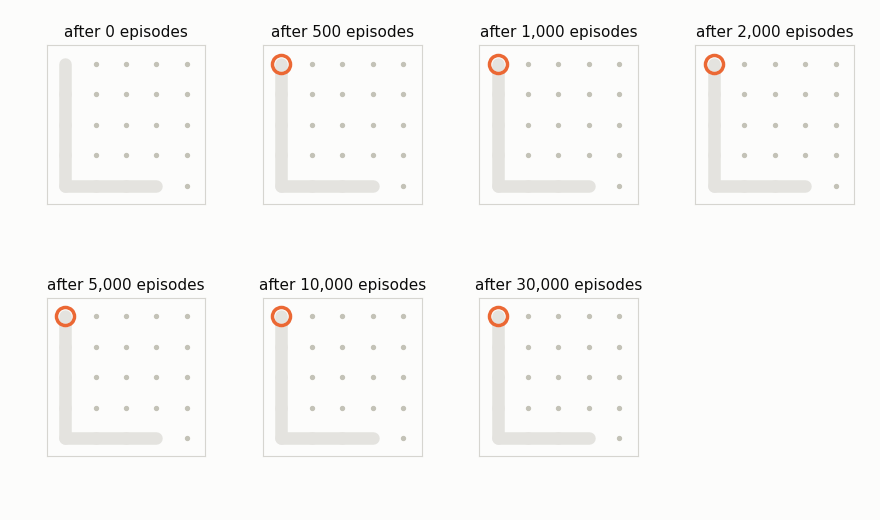

In [3]:
panels = [(env.letter, res_L["snapshots"][k]["history"], f"after {k:,} episodes") for k in SNAPSHOTS]
animate_episodes(panels, "../results/03_L_snapshots.gif", ncols=4)
Image(filename="../results/03_L_snapshots.gif")

**How to read this.** The greedy return (left) jumps from strongly negative to the optimum in a
few thousand episodes. The training return (middle) rises more slowly and stays below the optimum:
during training the agent still explores (ε > 0), so it keeps making deliberate random moves. It only
approaches the greedy return when ε becomes small (right).

## 2. The 10 letters, 5 runs each

50 trainings in total. **This cell takes about 3 minutes.**

In [4]:
runs = {}  # runs[letter] = list of result dicts (one per seed)
t_all = time.perf_counter()
for name in TRAINING_LETTERS:
    runs[name] = []
    for seed in SEEDS:
        env = LetterWritingEnv(name)
        res = q_learning(env, n_episodes=N_EPISODES, alpha=ALPHA, gamma=GAMMA, eval_every=500, seed=seed)
        res["policy"] = greedy_policy(res.pop("Q"))  # keep the policy, not the whole table (memory)
        runs[name].append(res)
    times = [r["time"] for r in runs[name]]
    print(f"{name}: {np.mean(times):.1f} s per run")
print(f"total: {time.perf_counter() - t_all:.0f} s")

I: 4.6 s per run
L: 2.3 s per run
T: 3.4 s per run
E: 4.3 s per run
F: 3.4 s per run
H: 4.4 s per run
N: 3.6 s per run
Z: 3.6 s per run
V: 2.7 s per run
X: 3.4 s per run
total: 178 s


In [5]:
rows = []
print(f"{'letter':<7}{'seg.':>5}{'% of v* (mean ± std)':>23}{'perfect':>9}{'optimal runs':>14}{'1st perfect (median)':>22}{'time/run':>10}")
for name, rs in runs.items():
    k = LetterWritingEnv(name).k
    pct = np.array([100 * r["eval_return"][-1] / v_star_mean[name] for r in rs])
    perfect = np.mean([r["eval_perfect"][-1] for r in rs])
    n_opt = sum(r["eval_return"][-1] >= v_star_mean[name] - 1e-6 for r in rs)
    first = [r["eval_episodes"][np.argmax(r["eval_perfect"] == 1)] if (r["eval_perfect"] == 1).any() else np.nan for r in rs]
    t = np.mean([r["time"] for r in rs])
    rows.append({"letter": name, "segments": k, "pct_optimum_mean": round(pct.mean(), 2), "pct_optimum_std": round(pct.std(), 2),
                 "perfect_final": perfect, "runs_reaching_optimum": int(n_opt),
                 "episodes_to_first_perfect_median": float(np.nanmedian(first)), "time_per_run_s": round(t, 2)})
    print(f"{name:<7}{k:>5}{pct.mean():>15.1f} ± {pct.std():<5.1f}{perfect:>9.0%}{n_opt:>10} / {len(rs)}"
          f"{np.nanmedian(first):>20,.0f}{t:>9.1f}s")

with open("../results/03_q_learning_summary.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
np.savez("../results/03_q_learning_curves.npz",
         episodes=runs["L"][0]["eval_episodes"],
         **{f"{name}_return": np.array([r["eval_return"] for r in rs]) for name, rs in runs.items()},
         **{f"{name}_perfect": np.array([r["eval_perfect"] for r in rs]) for name, rs in runs.items()})
print("\nsaved: results/03_q_learning_summary.csv, results/03_q_learning_curves.npz")

letter  seg.   % of v* (mean ± std)  perfect  optimal runs  1st perfect (median)  time/run
I          8           97.4 ± 1.0       100%         0 / 5               9,000      4.6s
L          7          100.0 ± 0.0       100%         5 / 5               5,000      2.3s
T          8           97.1 ± 1.0       100%         0 / 5               9,500      3.4s
E         12           97.4 ± 0.9       100%         0 / 5              10,500      4.3s
F          9           97.6 ± 1.0       100%         0 / 5               8,000      3.4s
H         12           93.4 ± 0.5       100%         0 / 5              12,500      4.4s
N         12           97.8 ± 1.1       100%         1 / 5               9,000      3.6s
Z         12           98.9 ± 1.4       100%         3 / 5               9,000      3.6s
V          8           99.4 ± 1.2       100%         4 / 5               7,000      2.7s
X          8           96.9 ± 1.4       100%         0 / 5              10,000      3.4s

saved: results/03_

**Columns:** *% of v\** = final greedy return as a percentage of the optimum; *perfect* = fraction
of (run, starting point) pairs where the final greedy policy draws the letter perfectly; *optimal
runs* = runs whose final greedy policy reaches exactly the optimum; *1st perfect* = number of
training episodes before the greedy policy first draws the letter perfectly from every starting point.

### Learning curves

Mean over the 5 runs (line) and range between the worst and the best run (band).

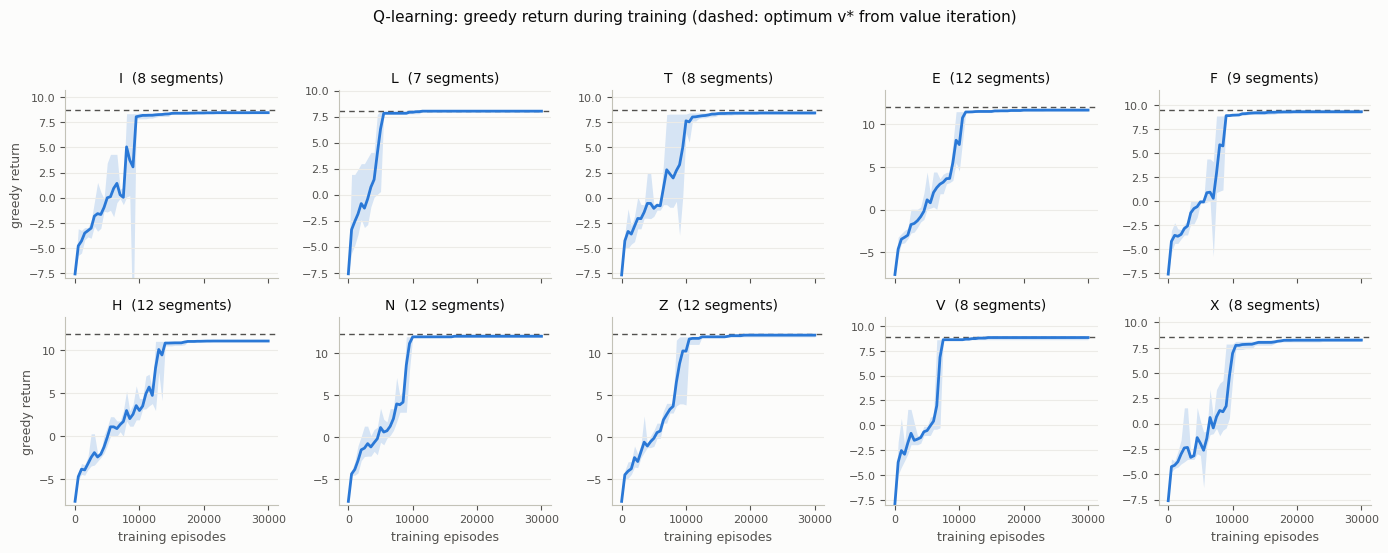

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5.6), sharex=True, facecolor=SURFACE)
for ax, (name, rs) in zip(axes.ravel(), runs.items()):
    ep = rs[0]["eval_episodes"]
    curves = np.array([r["eval_return"] for r in rs])
    ax.axhline(v_star_mean[name], color=MUTED, lw=1, ls=(0, (4, 3)))
    ax.fill_between(ep, curves.min(0), curves.max(0), color="#2a78d6", alpha=0.18, lw=0)
    ax.plot(ep, curves.mean(0), color="#2a78d6", lw=2)
    ax.set_ylim(-8, v_star_mean[name] + 2)
    style(ax, f"{name}  ({LetterWritingEnv(name).k} segments)")
for ax in axes[1]:
    ax.set_xlabel("training episodes", color=MUTED, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("greedy return", color=MUTED, fontsize=9)
fig.suptitle("Q-learning: greedy return during training (dashed: optimum v* from value iteration)",
             color=TEXT, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("../results/03_learning_curves.png", dpi=150, facecolor=SURFACE)
plt.show()

### The final drawings, compared with the optimum

Greedy policy of run 0 after training, from each natural starting point.

letter start     Q-learning steps  strokes   | optimal steps  strokes
I      (0, 1)                  15        1   |            11        1
I      (0, 3)                  15        1   |            11        1
I      (4, 1)                  11        1   |            11        1
I      (4, 3)                  11        1   |            11        1
L      (0, 0)                   8        1   |             8        1
L      (4, 3)                   8        1   |             8        1
T      (0, 0)                  11        1   |            11        1
T      (0, 4)                  15        1   |            11        1
T      (4, 2)                  11        1   |            11        1
E      (0, 3)                  15        2   |            15        1
E      (2, 2)                  17        2   |            18        1
E      (4, 3)                  15        2   |            15        1
F      (0, 3)                  14        1   |            12        1
F      (2, 2)       

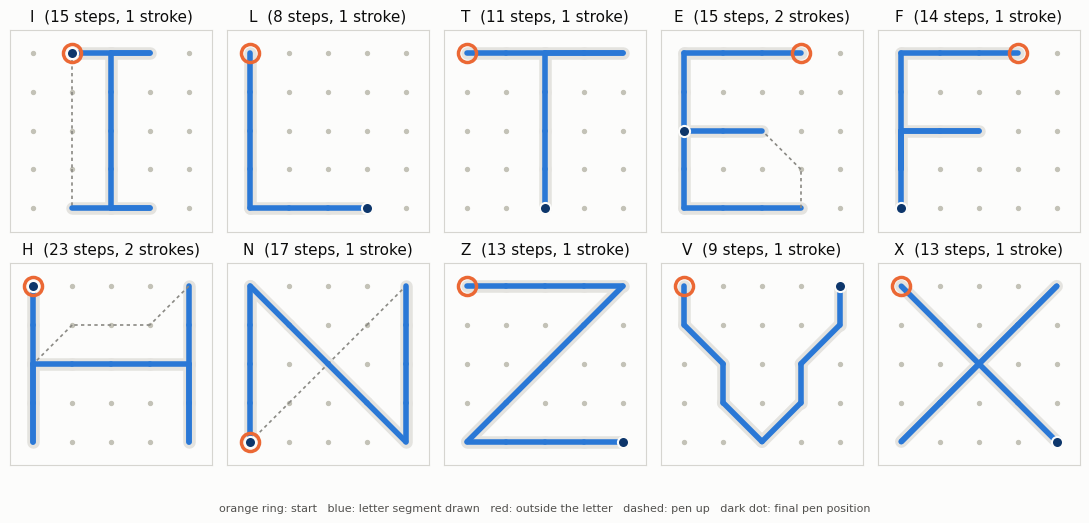

In [7]:
print(f"{'letter':<7}{'start':<9}{'Q-learning steps':>17}{'strokes':>9}{'   |':>4}{'optimal steps':>14}{'strokes':>9}")
panels = []
for name, rs in runs.items():
    env = LetterWritingEnv(name)
    for i, start in enumerate(env.letter.start_points):
        ep = play_policy(env, rs[0]["policy"], start, gamma=GAMMA)
        o = optimal[(name, str(start))]
        print(f"{name:<7}{str(start):<9}{ep['steps']:>17}{ep['strokes']:>9}{'   |':>4}{o['steps']:>14}{o['strokes']:>9}")
        if i == 0:
            panels.append((env.letter, ep["history"], f"{name}  ({ep['steps']} steps, {ep['strokes']} stroke{'s' * (ep['strokes'] > 1)})"))

plot_episodes(panels, path="../results/03_final_drawings.png")
plt.show()

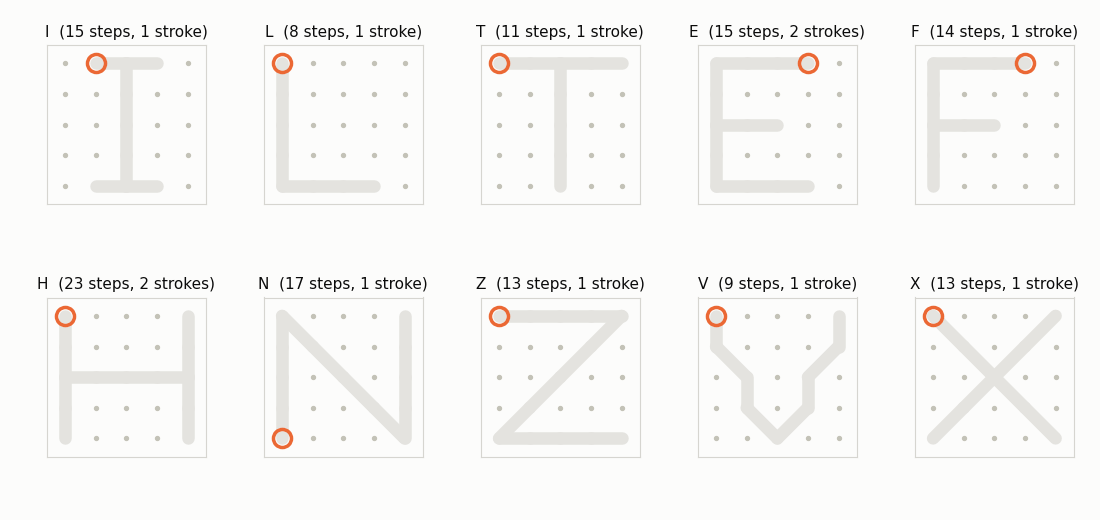

In [8]:
animate_episodes(panels, "../results/03_final_drawings.gif")
Image(filename="../results/03_final_drawings.gif")

## 3. Does longer training help? The letter H

H is the letter furthest from the optimum. We train it again with 100,000 episodes instead of 30,000
(one run, about 35 seconds) and look at how many states the agent has actually visited.

In [9]:
env = LetterWritingEnv("H")
res_long = q_learning(env, n_episodes=100_000, alpha=ALPHA, gamma=GAMMA, eval_every=2_000, seed=0)
visited = int((np.abs(res_long["Q"]).sum(axis=1) > 0).sum())
print(f"100,000 episodes: {100 * res_long['eval_return'][-1] / v_star_mean['H']:.1f} % of v*  "
      f"(30,000 episodes: {np.mean([100 * r['eval_return'][-1] / v_star_mean['H'] for r in runs['H']]):.1f} % on average)")
print(f"states visited at least once: {visited:,} of {env.n_states:,} ({100 * visited / env.n_states:.1f} %)")

100,000 episodes: 97.2 % of v*  (30,000 episodes: 93.4 % on average)
states visited at least once: 23,762 of 204,800 (11.6 %)


## What to notice

(The numbers below come from our test run; yours should be very close, since the seeds are fixed.)

- **Q-learning learns to write every letter without knowing the model.** In all 50 runs, the final greedy
  policy draws every letter perfectly (complete, no segment outside the letter, then STOP) from every
  natural starting point. The first perfect drawing from every start appears after about 5,000 (L) to
  12,500 (H) training episodes (median over the 5 runs).
- **It is fast**: 2 to 4 seconds per run of 30,000 episodes, about 2.5 minutes for the 50 runs.
- **But it is good, not optimal**: the final greedy return reaches 93 % (H) to 100 % (L) of the optimum.
  Only L reaches the exact optimum in all 5 runs (V: 4/5, Z: 3/5, N: 1/5, the others 0/5). The table of
  drawings shows two kinds of imperfection:
  - **detours**: from some starting points (I, T, N, X), the agent first travels with the pen up to
    *another* starting point and draws the letter from there, as it learned it best — 4 useless moves;
  - **lifting the pen**: for E, F and H the agent uses 2 strokes, while the optimum draws them in a single
    stroke by going back over segments already drawn. The agent's drawing is closer to how a person
    writes, but it costs −0.3 instead of a few −0.05 moves.
- **Why it does not find the optimum: exploration.** The optimal one-stroke drawings require long
  sequences of "going back over" moves that bring no immediate reward; random ε-greedy exploration
  rarely tries them. Even with 100,000 episodes, the agent has visited only about 12 % of the 204,800
  states of H, and reaches 97 % of the optimum instead of 93 %. Value iteration, on the contrary, looks
  at every state — but it needs the model.
- **The runs agree at the end** (standard deviation ≤ 1.4 % of the optimum), but differ a lot during
  learning (wide bands around 5,000–10,000 episodes): when the agent discovers the solution depends on luck.
- **Training return vs greedy return** (L, middle plot): the reward collected during training stays below
  the greedy return as long as ε is large, because the agent keeps making deliberate random moves. This
  is the cost of exploration; Q-learning is *off-policy*: it learns the greedy policy while behaving
  ε-greedily.

**For the debate:** Q-learning does not need the model and only visits the useful part of the state
space, but it gives no guarantee of reaching the optimum in limited time, and the result depends on
exploration and on the parameters (α, ε, number of episodes). Next step: SARSA and Monte Carlo on the
same letters, with the same budget, to compare.
